# Projeto IA002, Nível 1: Solver para o ARC-AGI-1

Este notebook resolve tarefas do **ARC-AGI-1** com um modelo de linguagem (LLM) do Google, o **Gemini 3.5 Flash Lite**.

O experimento compara **duas abordagens** para cada tarefa:

- **Fim a fim:** o modelo analisa os exemplos e produz diretamente a grade de resposta.
- **Código Python:** o modelo escreve um programa em Python, que é executado para produzir a resposta.

Cada abordagem é avaliada com **dois níveis de raciocínio**: **mínimo**, mais rápido, e **alto**, em que o modelo gera mais tokens de raciocínio antes da resposta final.

Ao final, o notebook produz uma tabela de resultados para a elaboração do relatório.

### Instruções de uso

1. Cada caixa cinza é uma **célula de código**. Para executar uma célula, selecione-a e pressione **Shift + Enter**, ou clique no botão ▶ à esquerda.
2. Execute as células **na ordem, de cima para baixo**, aguardando o término de cada uma.
3. Em caso de erro, leia a mensagem exibida abaixo da célula. A maioria dos problemas se resolve executando a célula novamente.
4. Se o notebook for fechado, execute-o novamente desde o início (menu **Ambiente de execução → Executar tudo**).

## Passo 1: Instalação da Biblioteca do Google

Esta célula instala a biblioteca de acesso ao Gemini. A instalação pode exibir várias linhas de texto.

In [1]:
%pip install -q -U --no-deps google-genai

## Passo 2: Chave da API do Google

O uso do Gemini exige uma **chave da API**, que é gratuita.

**Criação da chave (apenas uma vez):**

1. Acesse **aistudio.google.com/api-keys** com a sua conta Google.
2. Clique em **Create API key** (Criar chave de API) e copie a chave. Ela começa com `AIza`.

**Armazenamento da chave no Colab (recomendado):**

1. Na barra lateral esquerda do Colab, clique no ícone de **chave** (*Secrets*).
2. Clique em **Adicionar novo secret**.
3. Em **Nome**, escreva exatamente `GOOGLE_API_KEY`. Em **Valor**, cole a chave.
4. Ative a opção **Acesso ao notebook**.

Caso o *secret* não seja configurado, a célula abaixo solicitará a chave em uma caixa de texto.

**Atenção:** a chave é pessoal e secreta. Ela não deve ser incluída no código, no relatório nem em mensagens. Em caso de exposição, apague-a no AI Studio e crie uma nova.

In [2]:
import os
import getpass


def carregar_chave():
    """Busca a chave nos Secrets do Colab, depois em uma variável de ambiente e, por último, solicita a chave."""
    try:
        from google.colab import userdata
        chave = userdata.get("GOOGLE_API_KEY")
        if chave:
            return chave
    except Exception:
        pass
    if os.environ.get("GOOGLE_API_KEY"):
        return os.environ["GOOGLE_API_KEY"]
    return getpass.getpass("Cole a chave GOOGLE_API_KEY e pressione Enter: ")


CHAVE = carregar_chave().strip()
print("Chave carregada." if CHAVE else "Nenhuma chave encontrada. Consulte o Passo 2.")

Chave carregada.


## Passo 3: Configuração

Esta célula define o modelo, as 20 tarefas e as quatro configurações do experimento. As 10 primeiras são do conjunto de treino (*training*) e as 10 últimas do conjunto de avaliação (*evaluation*). **Nenhuma alteração é necessária.**

- `ESPERA_SEGUNDOS` é o intervalo entre duas chamadas ao Gemini, para respeitar o limite da chave gratuita.
- Para um teste rápido antes do experimento completo, altere `TESTE_RAPIDO = False` para `TESTE_RAPIDO = True`. Nesse caso, apenas 2 tarefas são executadas, uma de cada conjunto.

In [3]:
MODELO = "gemini-3.5-flash-lite"

# Conjunto (training ou evaluation) e identificador de cada tarefa
CAMINHOS = [
    "training/3aa6fb7a", "training/44d8ac46", "training/44f52bb0", "training/007bbfb7",
    "training/25ff71a9", "training/0a938d79", "training/1cf80156", "training/2013d3e2",
    "training/32597951", "training/9565186b",
    "evaluation/9a4bb226", "evaluation/aab50785", "evaluation/d47aa2ff", "evaluation/f5aa3634",
    "evaluation/93b4f4b3", "evaluation/e9b4f6fc", "evaluation/7c9b52a0", "evaluation/c658a4bd",
    "evaluation/50aad11f", "evaluation/7d18a6fb",
]

# (abordagem, nível de raciocínio)
CONFIGURACOES = [
    ("fim_a_fim", "minimal"),
    ("fim_a_fim", "high"),
    ("codigo", "minimal"),
    ("codigo", "high"),
]

ESPERA_SEGUNDOS = 1
TESTE_RAPIDO = False

if TESTE_RAPIDO:
    CAMINHOS = [CAMINHOS[0], CAMINHOS[10]]
print(len(CAMINHOS), "tarefas e", len(CONFIGURACOES), "configurações:", len(CAMINHOS) * len(CONFIGURACOES), "chamadas ao Gemini.")

20 tarefas e 4 configurações: 80 chamadas ao Gemini.


## Passo 4: Download das Tarefas

As tarefas são obtidas do repositório público do ARC-AGI-1 no GitHub, nas pastas `training` e `evaluation`. Cada tarefa contém alguns **exemplos de treino** (entrada e saída) e uma ou mais **entradas de teste**, cuja saída o solver deve determinar.

In [4]:
import json
import urllib.request

URL = "https://raw.githubusercontent.com/fchollet/ARC-AGI/master/data/{}.json"

tarefas = {}
conjunto = {}
for caminho in CAMINHOS:
    nome_conjunto, tarefa_id = caminho.split("/")
    with urllib.request.urlopen(URL.format(caminho)) as resposta:
        tarefas[tarefa_id] = json.load(resposta)
    conjunto[tarefa_id] = nome_conjunto
TAREFAS = list(tarefas)
print(len(tarefas), "tarefas obtidas:", ", ".join(TAREFAS))

20 tarefas obtidas: 3aa6fb7a, 44d8ac46, 44f52bb0, 007bbfb7, 25ff71a9, 0a938d79, 1cf80156, 2013d3e2, 32597951, 9565186b, 9a4bb226, aab50785, d47aa2ff, f5aa3634, 93b4f4b3, e9b4f6fc, 7c9b52a0, c658a4bd, 50aad11f, 7d18a6fb


## Passo 5: Visualização de uma Tarefa

Cada número de 0 a 9 corresponde a uma cor. Execute a célula para visualizar a primeira tarefa. Para visualizar outra, altere o índice entre colchetes em `TAREFAS[0]`, na última linha da célula, para um número de 0 a 19 (por exemplo, `TAREFAS[1]`).

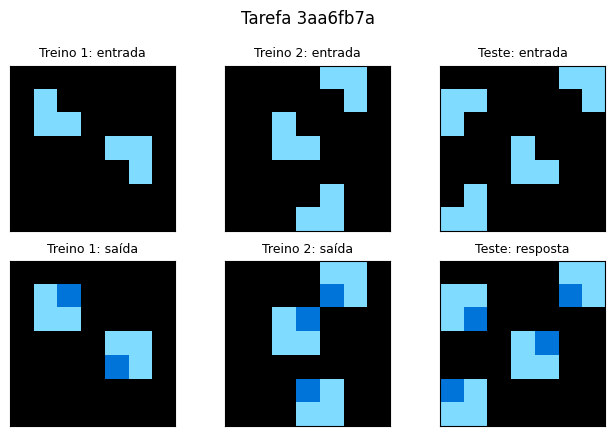

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

CORES = ListedColormap([
    "#000000", "#0074D9", "#FF4136", "#2ECC40", "#FFDC00",
    "#AAAAAA", "#F012BE", "#FF851B", "#7FDBFF", "#870C25",
])


def desenhar(eixo, grade, titulo):
    eixo.imshow(grade, cmap=CORES, vmin=0, vmax=9)
    eixo.set_title(titulo, fontsize=9)
    eixo.set_xticks([])
    eixo.set_yticks([])


def mostrar_tarefa(tarefa_id):
    tarefa = tarefas[tarefa_id]
    pares = [(p["input"], p["output"]) for p in tarefa["train"]]
    figura, eixos = plt.subplots(2, len(pares) + 1, figsize=(2.2 * (len(pares) + 1), 4.4))
    for i, (entrada, saida) in enumerate(pares):
        desenhar(eixos[0][i], entrada, f"Treino {i + 1}: entrada")
        desenhar(eixos[1][i], saida, f"Treino {i + 1}: saída")
    desenhar(eixos[0][-1], tarefa["test"][0]["input"], "Teste: entrada")
    desenhar(eixos[1][-1], tarefa["test"][0]["output"], "Teste: resposta")
    figura.suptitle(f"Tarefa {tarefa_id}")
    plt.tight_layout()
    plt.show()


mostrar_tarefa(TAREFAS[0])

## Passo 6: As Duas Abordagens

Esta célula define a comunicação com o Gemini e a verificação das respostas. **Basta executá-la.** Os dois *prompts* (as instruções enviadas ao modelo) estão nas variáveis `PROMPT_FIM_A_FIM` e `PROMPT_CODIGO`.

Na abordagem com código, o programa gerado é executado primeiro nos **exemplos de treino**, para verificar se a regra está correta, e depois na **entrada de teste**. Uma tarefa é considerada **resolvida** quando todas as respostas de teste são exatamente iguais às esperadas.

In [6]:
import re
import subprocess
import sys
import time

from google import genai
from google.genai import types

cliente = genai.Client(api_key=CHAVE)

PROMPT_FIM_A_FIM = """Solve this ARC-AGI-1 task. Infer the transformation from the training
input/output pairs, then apply it to each test input. Grids are lists of rows of
integers from 0 to 9, each integer is a color. The output size can differ from the input size.
Return only a JSON object in this format, without Markdown:
{"rule": "Short description of the rule.", "test": [{"output": [[0, 1], [2, 3]]}]}
Include one output grid for every test input, in the same order.

"""

PROMPT_CODIGO = """Solve this ARC-AGI-1 task by writing a Python program. Infer the transformation
from the training input/output pairs. Grids are lists of rows of integers from 0 to 9,
each integer is a color. The output size can differ from the input size.
Write a function transform(grid) that receives one input grid and returns the output grid
as a list of lists of integers. Use only the Python standard library.
Return only the code, inside a single ```python code block.

"""


def montar_tarefa(tarefa):
    """Retorna os exemplos de treino completos e apenas as entradas de teste, sem as respostas."""
    visivel = {"train": tarefa["train"], "test": [{"input": t["input"]} for t in tarefa["test"]]}
    return json.dumps(visivel)


def chamar_gemini(prompt, raciocinio):
    """Realiza uma chamada ao Gemini e retorna o texto e a contagem de tokens."""
    for tentativa in range(3):
        try:
            inicio = time.time()  # mede apenas a tentativa bem-sucedida, sem as esperas
            resposta = cliente.models.generate_content(
                model=MODELO,
                contents=prompt,
                config=types.GenerateContentConfig(
                    thinking_config=types.ThinkingConfig(thinking_level=raciocinio),
                ),
            )
            break
        except Exception as erro:
            if tentativa == 2:
                raise
            print(f"  Falha na chamada ({erro.__class__.__name__}). Nova tentativa em 60 segundos.")
            time.sleep(60)
    uso = resposta.usage_metadata
    custos = {
        "tokens_entrada": uso.prompt_token_count or 0,
        "tokens_raciocinio": uso.thoughts_token_count or 0,
        "tokens_saida": uso.candidates_token_count or 0,
        "segundos": round(time.time() - inicio, 1),
    }
    return resposta.text or "", custos


def extrair_json(texto):
    texto = texto.strip()
    if texto.startswith("```"):
        texto = "\n".join(texto.splitlines()[1:-1])
    return json.loads(texto)


def extrair_codigo(texto):
    blocos = re.findall(r"```(?:python)?\n(.*?)```", texto, flags=re.S)
    return blocos[0] if blocos else texto


def executar_codigo(codigo, grades, limite_segundos=10):
    """Executa transform() em cada grade, em um processo separado e com tempo limite."""
    programa = codigo + """

import json, sys
def _lista(g):
    return g.tolist() if hasattr(g, "tolist") else [[int(v) for v in linha] for linha in g]
_grades = json.loads(sys.stdin.read())
print(json.dumps([_lista(transform(g)) for g in _grades]))
"""
    try:
        processo = subprocess.run(
            [sys.executable, "-c", programa], input=json.dumps(grades),
            capture_output=True, text=True, timeout=limite_segundos,
        )
    except subprocess.TimeoutExpired:
        return None, "tempo esgotado"
    if processo.returncode != 0:
        linhas = processo.stderr.strip().splitlines()
        return None, linhas[-1] if linhas else "erro ao rodar o código"
    try:
        return json.loads(processo.stdout.strip().splitlines()[-1]), None
    except Exception:
        return None, "o código não devolveu uma grade válida"


def resolver(tarefa_id, abordagem, raciocinio):
    tarefa = tarefas[tarefa_id]
    esperadas = [t["output"] for t in tarefa["test"]]
    linha = {"tarefa": tarefa_id, "conjunto": conjunto[tarefa_id], "abordagem": abordagem, "raciocinio": raciocinio,
             "resolvida": False, "treino_ok": None, "erro": ""}
    if abordagem == "fim_a_fim":
        texto, custos = chamar_gemini(PROMPT_FIM_A_FIM + montar_tarefa(tarefa), raciocinio)
        linha.update(custos)
        try:
            respostas = [t["output"] for t in extrair_json(texto)["test"]]
            linha["resolvida"] = respostas == esperadas
        except Exception:
            linha["erro"] = "resposta fora do formato JSON"
    else:
        texto, custos = chamar_gemini(PROMPT_CODIGO + montar_tarefa(tarefa), raciocinio)
        linha.update(custos)
        codigo = extrair_codigo(texto)
        inicio_execucao = time.time()
        treino, erro = executar_codigo(codigo, [p["input"] for p in tarefa["train"]])
        linha["treino_ok"] = treino == [p["output"] for p in tarefa["train"]]
        teste, erro_teste = executar_codigo(codigo, [t["input"] for t in tarefa["test"]])
        linha["resolvida"] = teste == esperadas
        linha["erro"] = erro or erro_teste or ""
        linha["segundos"] = round(linha["segundos"] + time.time() - inicio_execucao, 1)
    return linha


print("Funções definidas. Execute o Passo 7.")

Funções definidas. Execute o Passo 7.


## Passo 7: Execução do Experimento

Esta célula resolve as 20 tarefas nas quatro configurações, com 80 chamadas ao Gemini. **A execução leva de 15 a 30 minutos**, pois o raciocínio alto é mais lento e há um intervalo de 1 segundo entre as chamadas. Mantenha a aba do Colab aberta durante a execução.

Para cada tarefa, são exibidos o resultado (`RESOLVIDA` ou `não resolvida`) e o número de tokens:

- **tokens de entrada:** o tamanho do *prompt* enviado;
- **tokens de raciocínio:** os tokens que o modelo gera antes da resposta final;
- **tokens de saída:** o tamanho da resposta.

In [7]:
linhas = []
for abordagem, raciocinio in CONFIGURACOES:
    print(f"\n=== {abordagem}, raciocínio {raciocinio} ===")
    for tarefa_id in TAREFAS:
        if linhas:
            time.sleep(ESPERA_SEGUNDOS)
        try:
            linha = resolver(tarefa_id, abordagem, raciocinio)
        except Exception as erro:
            linha = {"tarefa": tarefa_id, "conjunto": conjunto[tarefa_id], "abordagem": abordagem, "raciocinio": raciocinio,
                     "resolvida": False, "erro": f"falha na chamada: {erro}"}
        linhas.append(linha)
        situacao = "RESOLVIDA" if linha["resolvida"] else "não resolvida"
        print(f"{tarefa_id}: {situacao}  (entrada {linha.get('tokens_entrada', 0)}, "
              f"raciocínio {linha.get('tokens_raciocinio', 0)}, saída {linha.get('tokens_saida', 0)} tokens) {linha['erro']}")
print("\nFim do experimento.")


=== fim_a_fim, raciocínio minimal ===
3aa6fb7a: não resolvida  (entrada 882, raciocínio 0, saída 197 tokens) 
44d8ac46: não resolvida  (entrada 4049, raciocínio 0, saída 494 tokens) 
44f52bb0: não resolvida  (entrada 413, raciocínio 0, saída 52 tokens) 
007bbfb7: RESOLVIDA  (entrada 1545, raciocínio 0, saída 311 tokens) 
25ff71a9: RESOLVIDA  (entrada 435, raciocínio 0, saída 81 tokens) 
0a938d79: não resolvida  (entrada 5858, raciocínio 0, saída 974 tokens) 
1cf80156: não resolvida  (entrada 1912, raciocínio 0, saída 72 tokens) 
2013d3e2: RESOLVIDA  (entrada 1101, raciocínio 0, saída 53 tokens) 
32597951: não resolvida  (entrada 6223, raciocínio 0, saída 926 tokens) 
9565186b: não resolvida  (entrada 404, raciocínio 0, saída 61 tokens) 
9a4bb226: não resolvida  (entrada 2935, raciocínio 0, saída 979 tokens) 
aab50785: não resolvida  (entrada 3978, raciocínio 0, saída 139 tokens) 
d47aa2ff: não resolvida  (entrada 3574, raciocínio 0, saída 378 tokens) 
f5aa3634: não resolvida  (entrada

## Passo 8: Tabela de Resultados

A primeira tabela apresenta o resumo por configuração, que deve constar no relatório. A segunda apresenta o resultado de cada tarefa.

In [8]:
import pandas as pd

resultados = pd.DataFrame(linhas)
resumo = (
    resultados.groupby(["abordagem", "raciocinio"], sort=False)
    .agg(resolvidas=("resolvida", "sum"), tarefas=("tarefa", "count"),
         tokens_entrada=("tokens_entrada", "sum"), tokens_raciocinio=("tokens_raciocinio", "sum"),
         tokens_saida=("tokens_saida", "sum"), segundos=("segundos", "sum"))
    .reset_index()
)
display(resumo)
display(resultados)

,abordagem,raciocinio,resolvidas,tarefas,tokens_entrada,tokens_raciocinio,tokens_saida,segundos
0,fim_a_fim,minimal,3,20,53706,0,6346,96.5
1,fim_a_fim,high,18,20,53706,180967,5640,425.3
2,codigo,minimal,9,20,53426,0,55304,172.4
3,codigo,high,18,20,53426,222127,7951,580.9


,tarefa,conjunto,abordagem,raciocinio,resolvida,treino_ok,erro,tokens_entrada,tokens_raciocinio,tokens_saida,segundos
0,3aa6fb7a,training,fim_a_fim,minimal,False,None,,882,0,197,5.2
1,44d8ac46,training,fim_a_fim,minimal,False,None,,4049,0,494,4.7
2,44f52bb0,training,fim_a_fim,minimal,False,None,,413,0,52,5.6
3,007bbfb7,training,fim_a_fim,minimal,True,None,,1545,0,311,4.6
4,25ff71a9,training,fim_a_fim,minimal,True,None,,435,0,81,4.7
...,...,...,...,...,...,...,...,...,...,...,...
75,e9b4f6fc,evaluation,codigo,high,True,True,,3069,13363,481,30.3
76,7c9b52a0,evaluation,codigo,high,True,True,,3356,32712,823,81.9
77,c658a4bd,evaluation,codigo,high,True,True,,2926,14798,390,40.7
78,50aad11f,evaluation,codigo,high,True,True,,2654,19919,852,52.8


## Passo 9: Gravação dos Resultados

Esta célula cria o arquivo `resultados.csv`, com uma linha por tarefa e configuração, e inicia o download no Colab. Caso o download não seja iniciado, abra o ícone de **pasta** na barra lateral, clique nos três pontos ao lado de `resultados.csv` e escolha **Fazer download**.

In [9]:
resultados.to_csv("resultados.csv", index=False)
print("Arquivo resultados.csv criado.")
try:
    from google.colab import files
    files.download("resultados.csv")
except Exception:
    pass

Arquivo resultados.csv criado.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Passo 10: Elaboração do Relatório com o ChatGPT

Elabore o relatório com o auxílio do ChatGPT, a partir do arquivo `resultados.csv` e da tabela do Passo 8. **Confira os números**: eles devem coincidir com os da tabela.

O relatório deve ter **até duas páginas**, em PDF, com o seu nome completo no topo e as seguintes seções:

1. **Objetivo:** o que foi comparado.
2. **Configuração:** o modelo, as quatro configurações e as 20 tarefas.
3. **Resultados:** a tabela com tarefas resolvidas (de 20), tokens de entrada, raciocínio e saída, e tempo.
4. **Exemplos:** uma tarefa resolvida e uma não resolvida, com uma explicação breve.
5. **Conclusão:** a configuração com melhor desempenho e o seu custo em tokens.
6. **Uso de IA:** uma frase descrevendo como o ChatGPT foi utilizado.

## Entrega (Nível 1)

Um único arquivo `nome_sobrenome.zip`, enviado na tarefa do Moodle, contendo:

- este notebook **executado**, com as saídas visíveis (menu **Arquivo → Fazer download → Fazer download do .ipynb**), com o nome `nivel1.ipynb`;
- o arquivo `resultados.csv`;
- o relatório `relatorio.pdf`, com até duas páginas.